In [ ]:
import pandas as pd
import warnings

warnings.filterwarnings('ignore', category=UserWarning, module='openpyxl')

# Leer el archivo especificando la hoja correcta: 'Regresion'
df = pd.read_excel('/content/euribor_IPI_bonos10a_COMPLETO.xlsx', sheet_name='Regresion', header=5)
df.head(10)

,Fecha,País ISO,Área BCE,Rendimiento BCE,Inflación HICP interanual (%),Estado bonos,Estado IPC,IPP país (2021=100),Estado IPP Eurostat,Desempleo país (%),...,"Títulos públicos (% PIB, mensual)",Estado deuda BCE,Euríbor 12M (% anual),Fecha cotización Euríbor,Desfase Euríbor (días),"IPI país (2021=100, SCA)",IPI variación interanual (%),Estado IPI Eurostat,Bono soberano 10 años (% anual),Estado bono 10a Eurostat
0,2010-06-30,CZ,Czechia (CZ),4.2000,0.9,A,A,87.1,NaN,7.2,...,26.3032,A,1.306,2010-06-30,0,77.5,7.34072,Disponible,4.26,Publicado
1,2010-06-30,DE,Germany (DE),4.1005,0.9,A,A,84.6,NaN,6.6,...,51.7660,A,1.306,2010-06-30,0,94.4,10.53864,Disponible,2.54,Publicado
2,2010-06-30,IT,Italy (IT),0.0453,1.4,A,A,86.8,NaN,8.6,...,95.0195,A,1.306,2010-06-30,0,103.8,10.54313,Disponible,4.10,Publicado
3,2010-07-31,CZ,Czechia (CZ),4.2000,1.6,A,A,87.1,NaN,7.3,...,27.7060,A,1.417,2010-07-30,1,78.0,10.63830,Disponible,3.97,Publicado
4,2010-07-31,DE,Germany (DE),4.1005,1.2,A,A,84.8,NaN,6.5,...,52.8207,A,1.417,2010-07-30,1,94.4,11.84834,Disponible,2.62,Publicado
5,2010-07-31,IT,Italy (IT),0.0453,1.8,A,A,87.0,NaN,8.5,...,96.3471,A,1.417,2010-07-30,1,103.6,7.80437,Disponible,4.03,Publicado
6,2010-08-31,CZ,Czechia (CZ),4.2000,1.5,A,A,86.7,NaN,7.1,...,28.2724,A,1.414,2010-08-31,0,80.3,9.54980,Disponible,3.56,Publicado
7,2010-08-31,DE,Germany (DE),4.1005,1.0,A,A,84.7,NaN,6.4,...,53.3958,A,1.414,2010-08-31,0,95.6,11.68224,Disponible,2.35,Publicado
8,2010-08-31,IT,Italy (IT),0.0453,1.8,A,A,87.2,NaN,8.5,...,96.0540,A,1.414,2010-08-31,0,107.4,14.37700,Disponible,3.80,Publicado
9,2010-09-30,CZ,Czechia (CZ),4.2000,1.8,A,A,87.0,NaN,6.9,...,29.9408,A,1.433,2010-09-30,0,81.7,11.45975,Disponible,3.34,Publicado


In [ ]:
import pandas as pd

# Leemos el archivo sin omitir ninguna fila de cabecera (header=None)
# para inspeccionar la estructura real de la hoja 'Regresion'.
df_raw = pd.read_excel('/content/euribor_con_IPI_completo.xlsx', sheet_name='Regresion', header=None)

print("Dimensiones de la hoja leída:", df_raw.shape)
print("\n--- Primeras 15 filas reales en el Excel (incluyendo celdas vacías) ---")
display(df_raw.head(15))

print("\n--- Resumen de valores nulos por columna con la lectura actual (header=5) ---")
print(df.isnull().sum())

FileNotFoundError: [Errno 2] No such file or directory: '/content/euribor_con_IPI_completo.xlsx'

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    KFold,
    StratifiedKFold,
    RepeatedStratifiedKFold,
    GroupKFold,
    cross_val_score,
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LinearRegression


pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

In [ ]:

df.columns

Index(['Fecha', 'País ISO', 'Área BCE', 'Rendimiento BCE',
       'Inflación HICP interanual (%)', 'Estado bonos', 'Estado IPC',
       'IPP país (2021=100)', 'Estado IPP Eurostat', 'Desempleo país (%)',
       'Estado desempleo', 'Títulos públicos (% PIB, mensual)',
       'Estado deuda BCE', 'Euríbor 12M (% anual)', 'Fecha cotización Euríbor',
       'Desfase Euríbor (días)', 'IPI país (2021=100, SCA)',
       'IPI variación interanual (%)', 'Estado IPI Eurostat'],
      dtype='object')

,Rendimiento BCE,Inflación HICP interanual (%),IPP país (2021=100),Desempleo país (%),"Títulos públicos (% PIB, mensual)",Euríbor 12M (% anual),"IPI país (2021=100, SCA)",Bono soberano 10 años (% anual)
Rendimiento BCE,1.000,0.178,0.449,-0.145,0.023,0.517,0.050,0.699
Inflación HICP interanual (%),0.178,1.000,0.561,-0.247,-0.124,0.295,0.178,0.423
IPP país (2021=100),0.449,0.561,1.000,-0.185,-0.118,0.680,0.271,0.704
Desempleo país (%),-0.145,-0.247,-0.185,1.000,0.322,-0.157,-0.044,-0.230
"Títulos públicos (% PIB, mensual)",0.023,-0.124,-0.118,0.322,1.000,-0.098,-0.165,-0.055
Euríbor 12M (% anual),0.517,0.295,0.680,-0.157,-0.098,1.000,0.233,0.706
"IPI país (2021=100, SCA)",0.050,0.178,0.271,-0.044,-0.165,0.233,1.000,0.174
Bono soberano 10 años (% anual),0.699,0.423,0.704,-0.230,-0.055,0.706,0.174,1.000


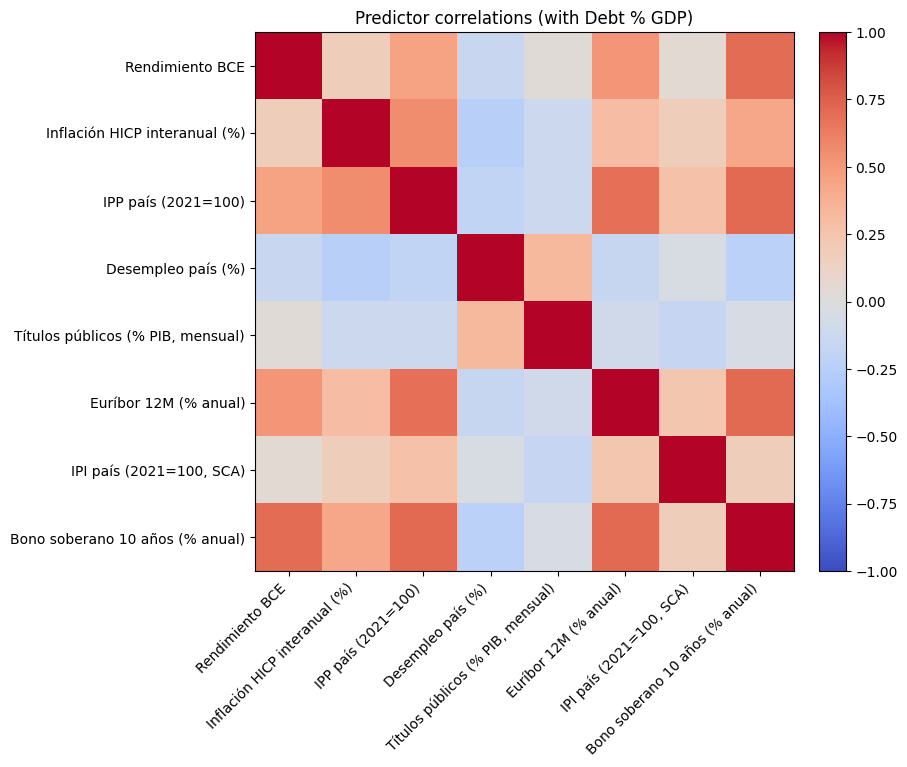

In [ ]:
import matplotlib.pyplot as plt

correlation_features = [
    "Rendimiento BCE",
    "Inflación HICP interanual (%)",
    "IPP país (2021=100)",
    "Desempleo país (%)",
    "Títulos públicos (% PIB, mensual)",
    "Euríbor 12M (% anual)",
    "IPI país (2021=100, SCA)",
    "Bono soberano 10 años (% anual)"
]

# correlation matrix for the selected predictors.
corr = df[correlation_features].corr()
display(corr.round(3))

# Visualize the correlation matrix with imshow.
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(correlation_features)))
ax.set_yticks(range(len(correlation_features)))
ax.set_xticklabels(correlation_features, rotation=45, ha="right")
ax.set_yticklabels(correlation_features)
ax.set_title("Predictor correlations (with Debt % GDP)")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.show()

In [ ]:
# Asegura que la columna sea datetime (usamos 'Fecha' con F mayúscula)
df['Fecha'] = pd.to_datetime(df['Fecha'], dayfirst=True)

# Quédate con las fechas hasta el 31-01-2025 inclusive
df_filtrado = df[df['Fecha'] <= '2025-01-31']

# Agrupa por fecha
resultado = df_filtrado.groupby('Fecha').sum(numeric_only=True)

df_test = df[df['Fecha'] >= '2025-01-31']

resultado_test = df_test.groupby('Fecha').sum(numeric_only=True)

In [ ]:
feature_simple = [
    "Inflación HICP interanual (%)",
    "IPP país (2021=100)",
    "Desempleo país (%)",
    "Títulos públicos (% PIB, mensual)",
    "Euríbor 12M (% anual)",
    "IPI país (2021=100, SCA)",

]
df_model = df_filtrado
target = "Bono soberano 10 años (% anual)"

X = df_model[feature_simple]
y = df_model[target]

# Dividir en entrenamiento (train) y validación (validation)
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
)

# Usar el conjunto df_test definido previamente para pruebas (test)
df_model_test = df_test
X_test = df_model_test[feature_simple]
y_test = df_model_test[target]

# Corregido: Agregamos "test" a la lista de "split" para que coincida en longitud con "n"
pd.DataFrame({
    "split": ["train", "validation", "test"],
    "n": [len(X_train), len(X_val), len(X_test)],
})

,split,n
0,train,1404
1,validation,351
2,test,463


In [ ]:
# TODO: initialize a Linear Regression model from scikit-learn
df_model = LinearRegression()

# Corregimos los NaNs en los conjuntos ya divididos
y_train = y_train.fillna(0)
y_val = y_val.fillna(0)

# TODO: fit the linear regression model using only the training data.
df_model.fit(X_train, y_train)

# TODO: generate predictions for train and validation.
train_pred_simple = df_model.predict(X_train)
val_pred_simple = df_model.predict(X_val)

# Corregido: Usamos 'feature_simple' en lugar de 'features_multi' y 'df_model' en lugar de 'multi_model'
coef_table = pd.DataFrame({
    "predictor": feature_simple,
    "coefficient": df_model.coef_,
})

display(coef_table)

,predictor,coefficient
0,Inflación HICP interanual (%),0.082787
1,IPP país (2021=100),0.009956
2,Desempleo país (%),-0.048370
3,"Títulos públicos (% PIB, mensual)",0.004027
4,Euríbor 12M (% anual),0.570027
5,"IPI país (2021=100, SCA)",-0.008861


In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display
from statsmodels.stats.stattools import durbin_watson

# Añadir el intercepto y ajustar sobre los mismos datos de entrenamiento.
# Conservamos df_model, tu modelo de scikit-learn.
X_train_sm = sm.add_constant(X_train, has_constant="add")
modelo_ols = sm.OLS(y_train, X_train_sm, missing="raise").fit()

# Tabla de coeficientes.
ic = modelo_ols.conf_int()

tabla_coeficientes = pd.DataFrame({
    "b": modelo_ols.params,
    "Error estándar": modelo_ols.bse,
    "t": modelo_ols.tvalues,
    "p-valor": modelo_ols.pvalues,
    "IC 95% inferior": ic.iloc[:, 0],
    "IC 95% superior": ic.iloc[:, 1],
    "Significativo al 5%": modelo_ols.pvalues < 0.05,
})
tabla_coeficientes.index.name = "Variable"

# Métricas del ajuste.
tabla_metricas = pd.Series({
    "N.º de observaciones": int(modelo_ols.nobs),
    "R² entrenamiento": modelo_ols.rsquared,
    "R² ajustado": modelo_ols.rsquared_adj,
    "F": modelo_ols.fvalue,
    "p-valor de F": modelo_ols.f_pvalue,
    "Durbin-Watson (orden actual de las filas)": durbin_watson(
        modelo_ols.resid
    ),
    "RMSE entrenamiento": np.sqrt(np.mean(modelo_ols.resid ** 2)),
    "MAE entrenamiento": np.mean(np.abs(modelo_ols.resid)),
    "AIC": modelo_ols.aic,
    "BIC": modelo_ols.bic,
}, name="Valor").to_frame()
tabla_metricas.index.name = "Métrica"

# Evaluación predictiva en validación usando tu modelo original.
errores_val = y_val.to_numpy() - val_pred_simple

tabla_validacion = pd.Series({
    "R² validación": df_model.score(X_val, y_val),
    "RMSE validación": np.sqrt(np.mean(errores_val ** 2)),
    "MAE validación": np.mean(np.abs(errores_val)),
}, name="Valor").to_frame()

display(tabla_coeficientes)
display(tabla_metricas)
display(tabla_validacion)

,b,Error estándar,t,p-valor,IC 95% inferior,IC 95% superior,Significativo al 5%
Variable,,,,,,,
const,0.780278,0.400883,1.946398,5.180718e-02,-0.006120,1.566676,False
Inflación HICP interanual (%),0.082787,0.010131,8.171797,6.739280e-16,0.062914,0.102661,True
IPP país (2021=100),0.009956,0.002365,4.209933,2.717649e-05,0.005317,0.014596,True
Desempleo país (%),-0.048370,0.012573,-3.847288,1.248156e-04,-0.073033,-0.023707,True
"Títulos públicos (% PIB, mensual)",0.004027,0.001274,3.160521,1.608676e-03,0.001528,0.006527,True
Euríbor 12M (% anual),0.570027,0.023915,23.835075,1.221289e-105,0.523113,0.616941,True
"IPI país (2021=100, SCA)",-0.008861,0.003773,-2.348627,1.898153e-02,-0.016262,-0.001460,True


,Valor
Métrica,
N.º de observaciones,1.404000e+03
R² entrenamiento,5.987863e-01
R² ajustado,5.970632e-01
F,3.474892e+02
p-valor de F,7.988645e-273
Durbin-Watson (orden actual de las filas),2.038237e+00
RMSE entrenamiento,1.149453e+00
MAE entrenamiento,8.439733e-01
AIC,4.389494e+03


,Valor
R² validación,0.610329
RMSE validación,1.324106
MAE validación,0.884783


Pasamamos a RANDOM FOREST porque el modelo porque el r^2 en validacion es del 0.249 lo que indica que no hay una relacion lineal entre las variables, no elimino ninguna variable porque todas son significativas a un 95% de confianza.

In [ ]:

from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
)

# 1. Crear el modelo con una configuración inicial reproducible.
modelo_rf = RandomForestRegressor(
    n_estimators=300,       # Número de árboles.
    max_depth=10,         # Sin límite de profundidad.
    min_samples_leaf=1,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

# 2. Entrenar únicamente con los datos de entrenamiento.
modelo_rf.fit(X_train, y_train)

# 3. Generar predicciones.
train_pred_rf = modelo_rf.predict(X_train)
val_pred_rf = modelo_rf.predict(X_val)
test_pred_rf = modelo_rf.predict(X_test)

# 4. Tabla de métricas para cada conjunto.
filas = []

for conjunto, y_real, y_pred in [
    ("Entrenamiento", y_train, train_pred_rf),
    ("Validación", y_val, val_pred_rf),
    ("Test", y_test, test_pred_rf),
]:
    filas.append({
        "Conjunto": conjunto,
        "N.º de observaciones": len(y_real),
        "R²": r2_score(y_real, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)),
        "MAE": mean_absolute_error(y_real, y_pred),
    })

tabla_metricas_rf = pd.DataFrame(filas).set_index("Conjunto")
display(tabla_metricas_rf)

# 5. Importancia de las variables basada en reducción de impureza.
tabla_importancias_rf = pd.DataFrame({
    "Variable": X_train.columns,
    "Importancia": modelo_rf.feature_importances_,
}).sort_values("Importancia", ascending=False).reset_index(drop=True)

display(tabla_importancias_rf)

,N.º de observaciones,R²,RMSE,MAE
Conjunto,,,,
Entrenamiento,1404,0.968348,0.322853,0.211652
Validación,351,0.877305,0.742996,0.390864
Test,463,0.528374,0.763894,0.439230


,Variable,Importancia
0,Euríbor 12M (% anual),0.569232
1,IPP país (2021=100),0.128836
2,"Títulos públicos (% PIB, mensual)",0.107683
3,Inflación HICP interanual (%),0.088761
4,Desempleo país (%),0.088412
5,"IPI país (2021=100, SCA)",0.017076


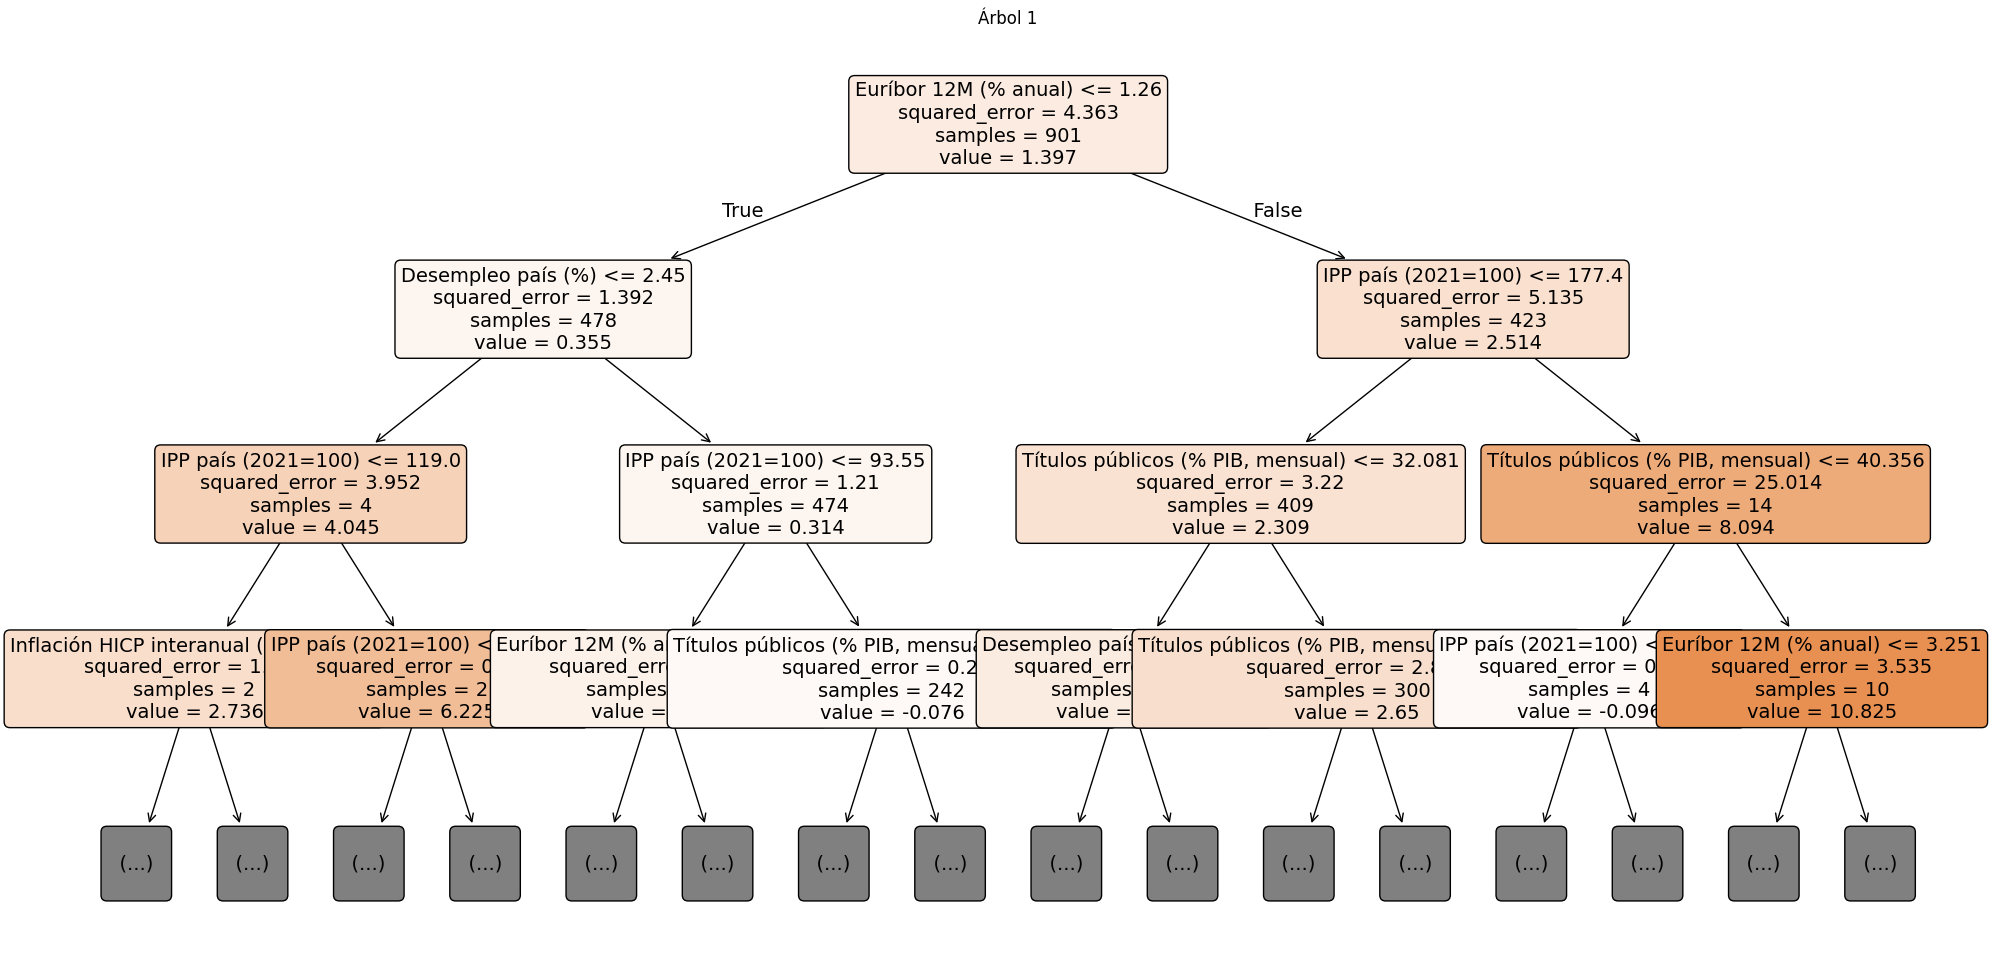

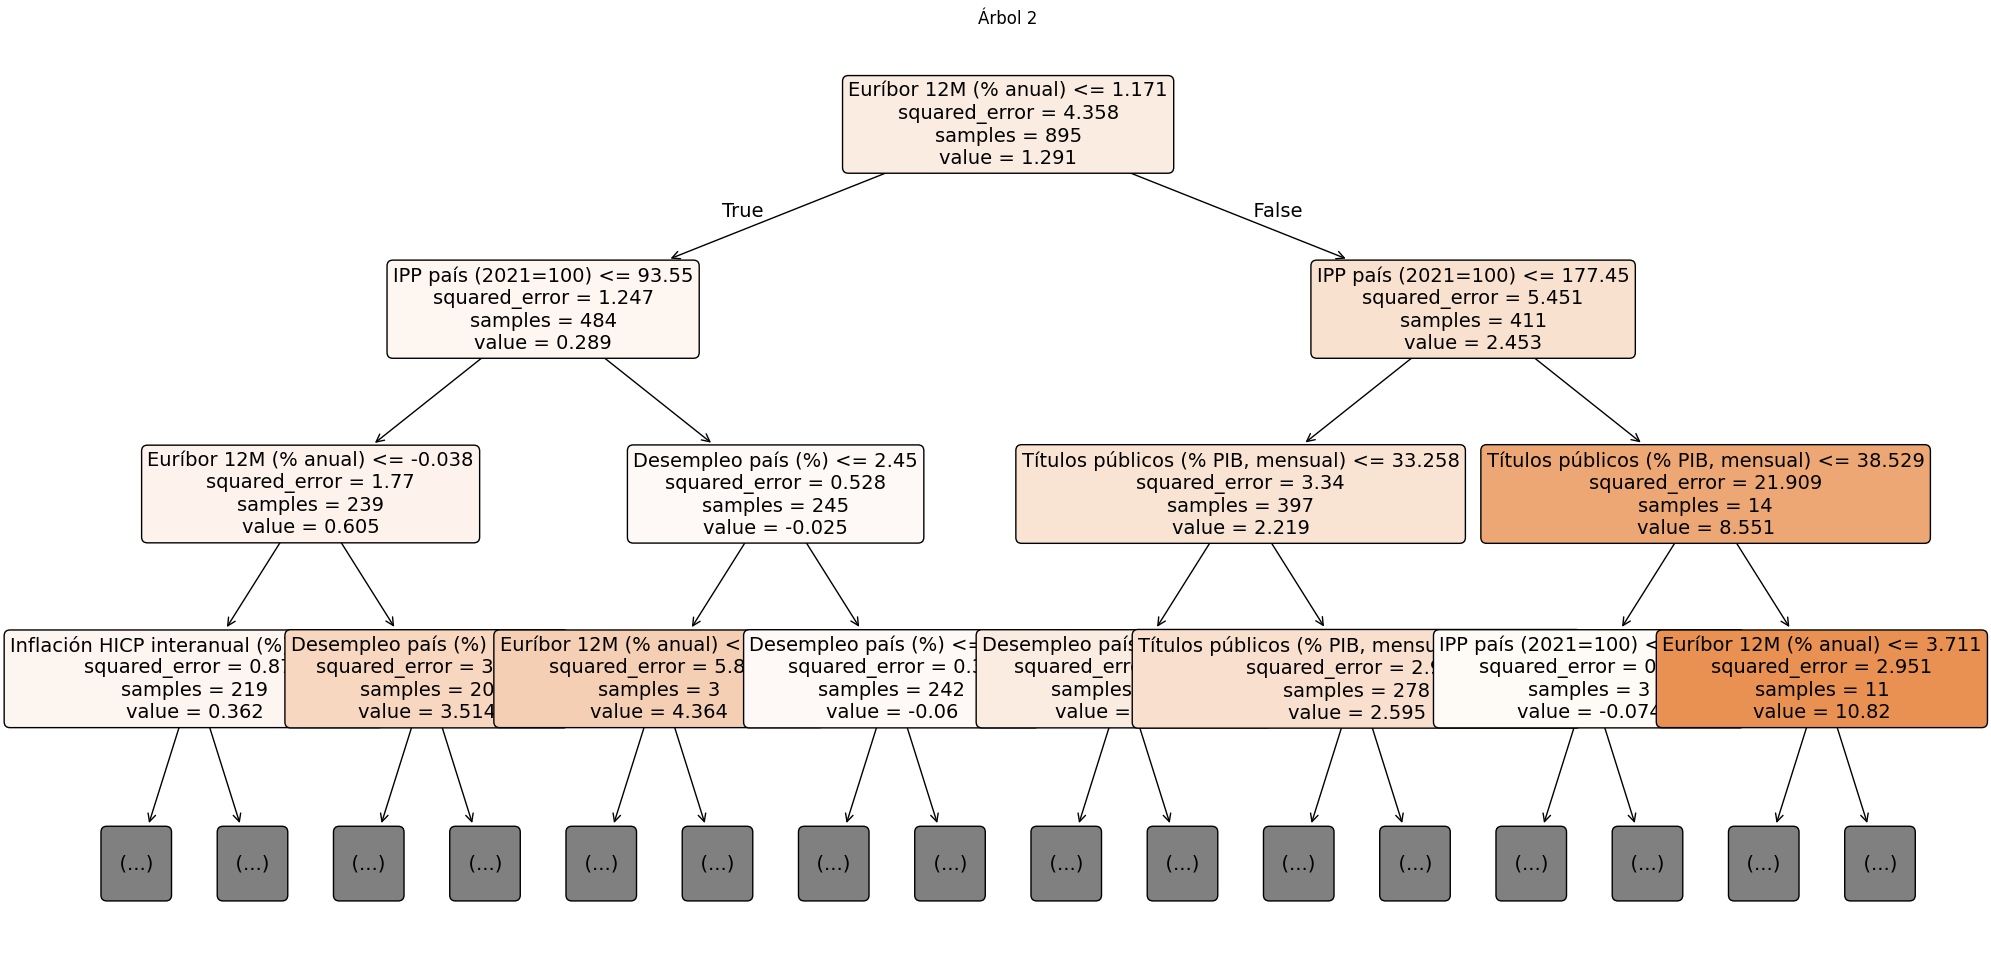

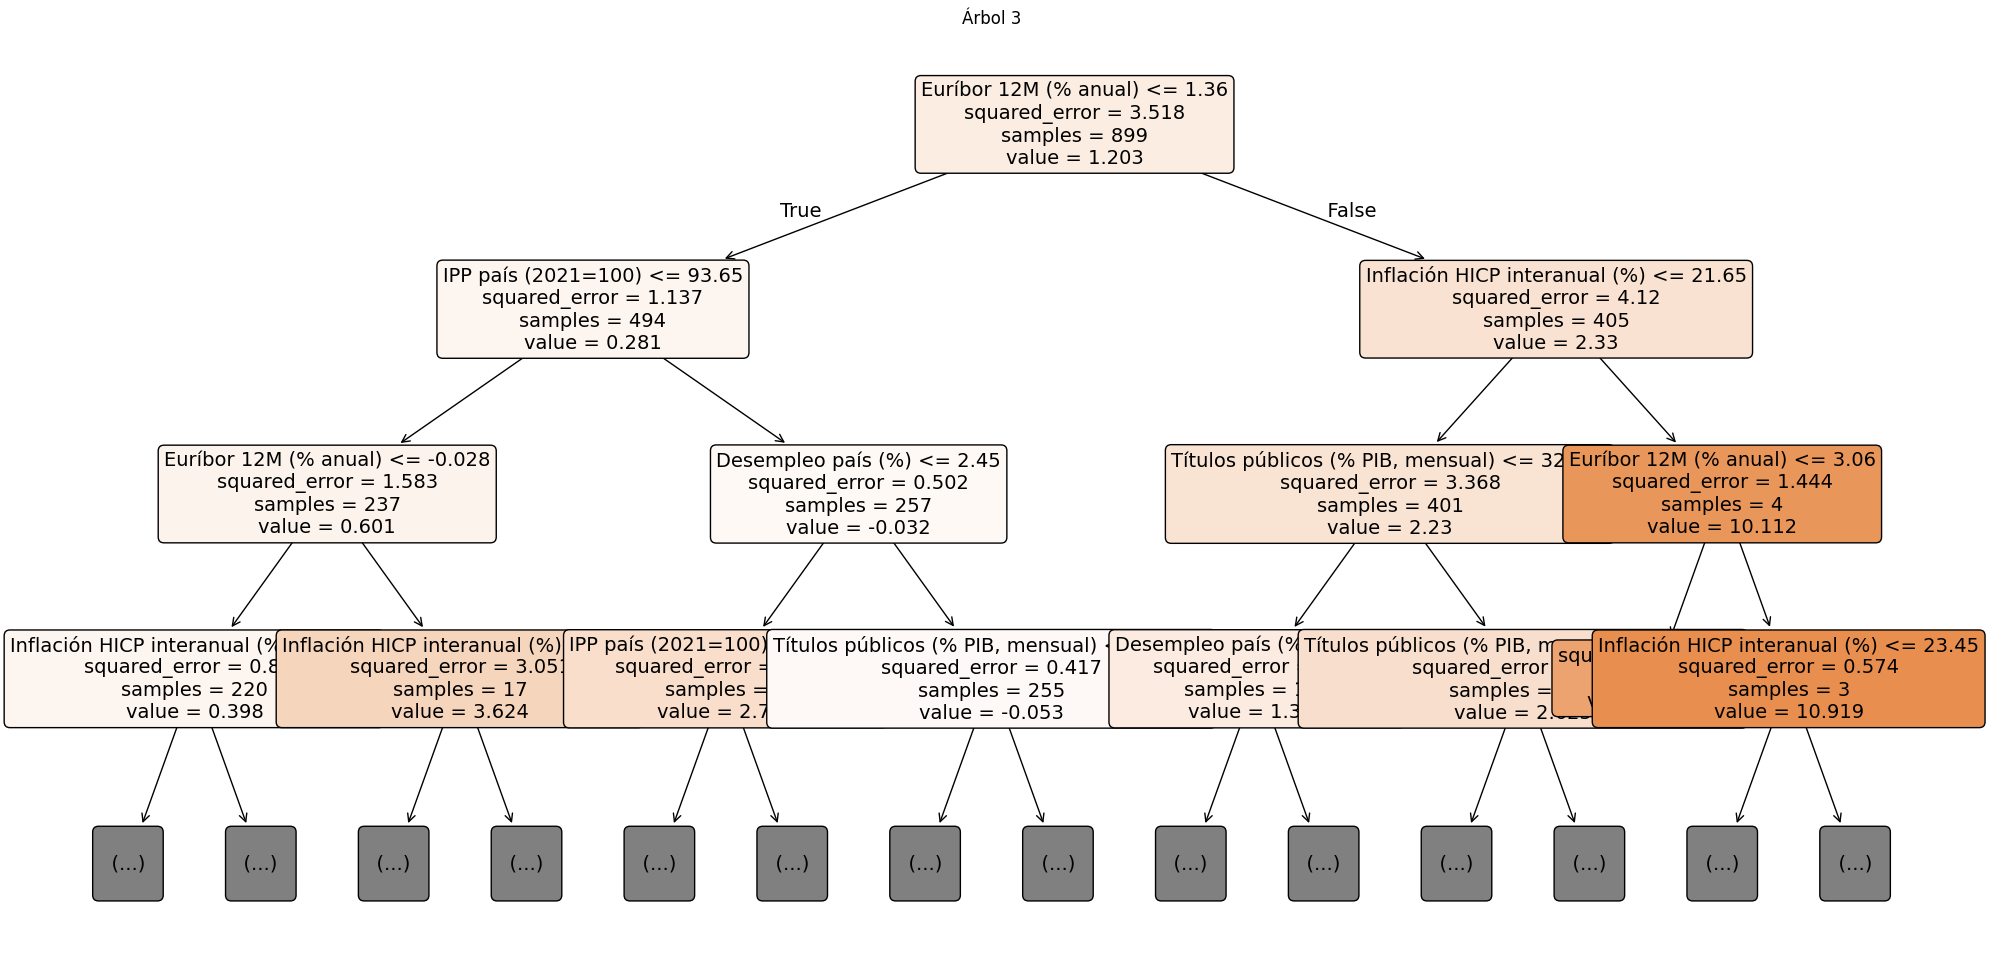

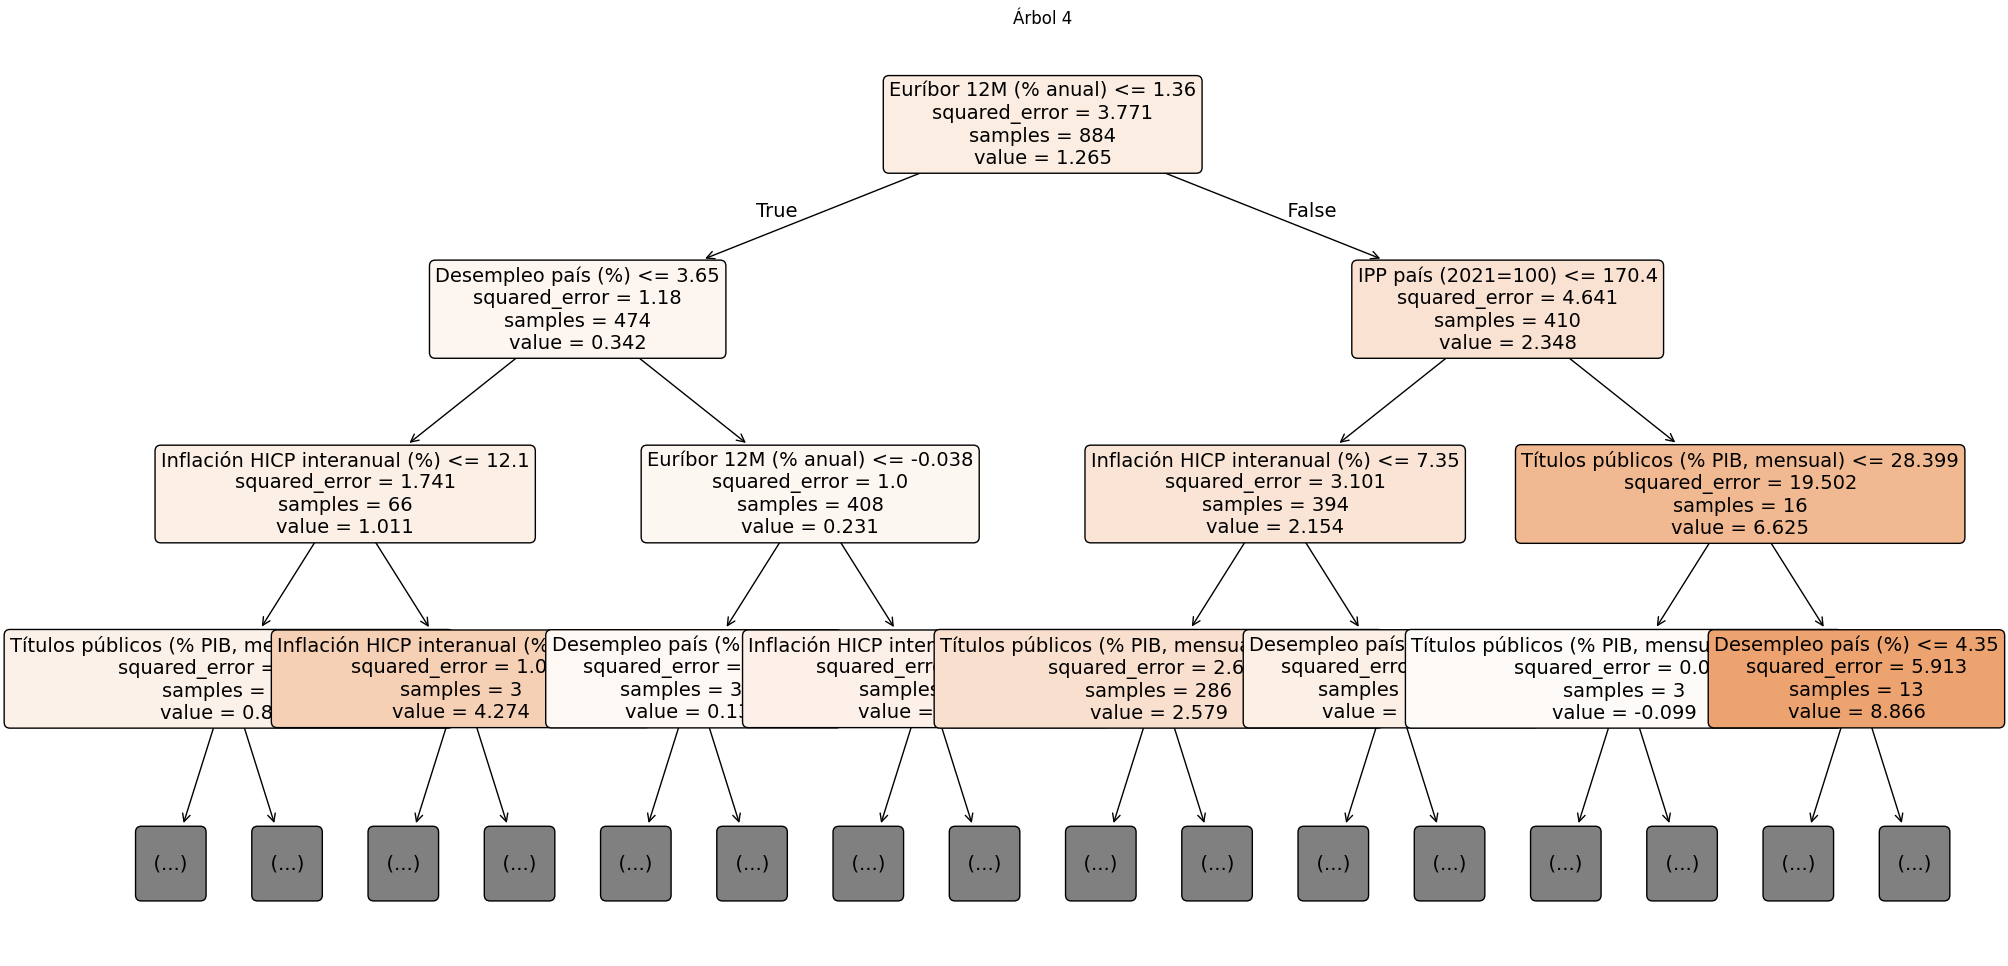

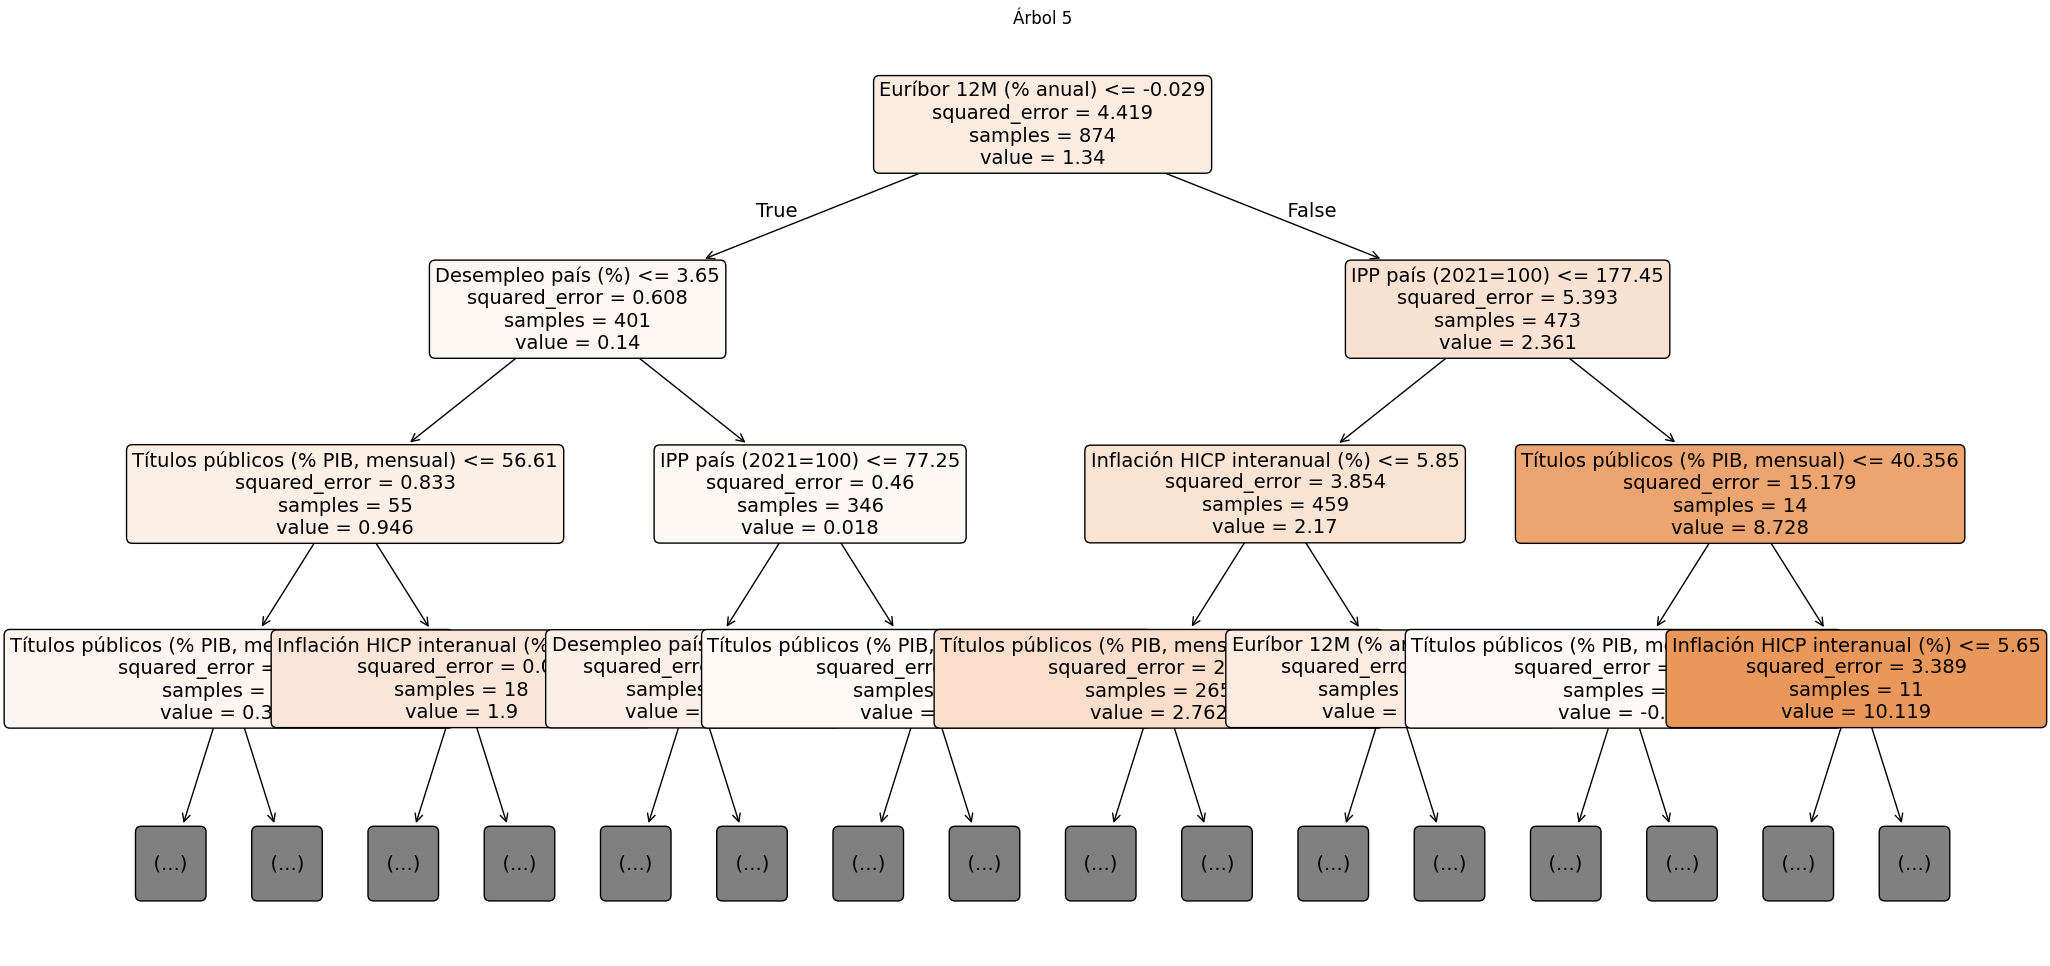

In [ ]:
from sklearn.tree import plot_tree

for i in range(5):
    plt.figure(figsize=(24, 12))

    plot_tree(
        modelo_rf.estimators_[i],
        feature_names=X_train.columns,
        filled=True,
        rounded=True,
        max_depth=3, # Reducido temporalmente para visualizar mejor, puedes cambiarlo de nuevo a 10 si lo prefieres
        fontsize=14
    )

    plt.title(f"Árbol {i + 1}")
    plt.show()

In [ ]:

from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
import pandas as pd

# Mismas variables utilizadas en el entrenamiento
X_vif = X_train.astype(float).dropna()

# Añadimos el intercepto
X_vif_const = sm.add_constant(X_vif)

# Calculamos el VIF de cada variable, excluyendo el intercepto
tabla_vif = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif_const.values, i)
        for i in range(1, X_vif_const.shape[1])
    ]
})

print(tabla_vif.sort_values("VIF", ascending=False))


In [ ]:

import statsmodels.api as sm
import pandas as pd

euribor = "Euríbor 12M (% anual)"
ipp = "IPP país (2021=100)"

# Muestra común para ambos modelos
datos = X_train.copy()
datos["Y"] = y_train
datos = datos.dropna()

y = datos["Y"]
X_con = datos[feature_simple]

# Modelo con euríbor
modelo_con = sm.OLS(
    y, sm.add_constant(X_con)
).fit()

# Modelo sin euríbor
X_sin = X_con.drop(columns=[euribor])
modelo_sin = sm.OLS(
    y, sm.add_constant(X_sin)
).fit()

comparacion = pd.DataFrame({
    "Modelo": ["Sin euríbor", "Con euríbor"],
    "Coeficiente IPP": [
        modelo_sin.params[ipp],
        modelo_con.params[ipp]
    ],
    "Error estándar IPP": [
        modelo_sin.bse[ipp],
        modelo_con.bse[ipp]
    ],
    "p-valor IPP": [
        modelo_sin.pvalues[ipp],
        modelo_con.pvalues[ipp]
    ],
    "R2 ajustado": [
        modelo_sin.rsquared_adj,
        modelo_con.rsquared_adj
    ]
})

display(comparacion)


In [ ]:
df_filtrado = df[df['Fecha'] <= '2025-01-31']
df_test = df[df['Fecha'] >= '2025-01-31']

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

DISTRIBUCIÓN DE LOS FOLDS


,Inicio,Fin,Observaciones
Fold,,,
1,2010-06-30,2020-05-31,355
2,2020-06-30,2021-07-31,338
3,2021-08-31,2022-09-30,346
4,2022-10-31,2023-10-31,332
5,2023-11-30,2024-12-31,356


RESULTADOS POR FOLD


,Fold,N train,N validación,R2 train,R2 validación,Diferencia R2,MAE train,MAE validación,RMSE train,RMSE validación
0,1,1372,355,0.982,0.755,0.227,0.192,0.487,0.257,0.609
1,2,1389,338,0.976,0.680,0.297,0.208,0.364,0.282,0.519
2,3,1381,346,0.985,0.604,0.382,0.166,0.756,0.225,1.206
3,4,1395,332,0.979,0.803,0.176,0.193,0.496,0.252,0.637
4,5,1371,356,0.982,0.773,0.210,0.192,0.386,0.251,0.528



PROMEDIOS DE LOS 5 FOLDS


,Promedio
R2 train,0.981
R2 validación,0.723
Diferencia R2,0.258
MAE train,0.190
MAE validación,0.498
RMSE train,0.253
RMSE validación,0.700


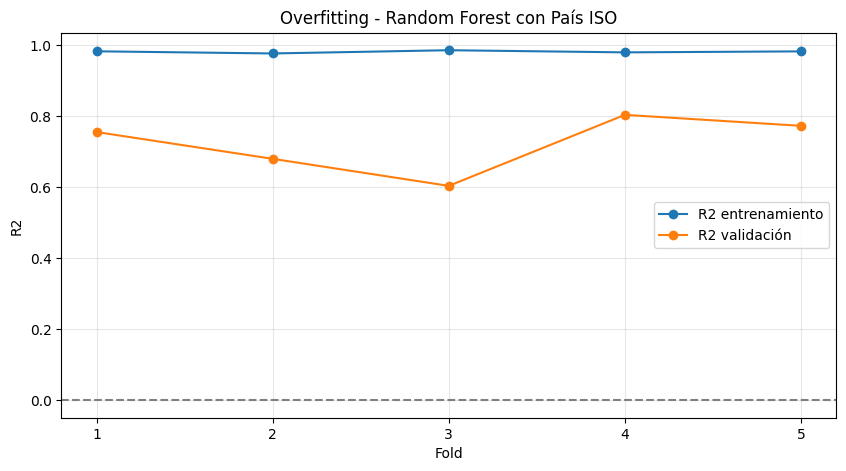


Test reservado: 463
No se ha utilizado test para entrenar ni validar.


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# ==========================================
# 1. VARIABLES DEL MODELO
# ==========================================

features = [
    "Inflación HICP interanual (%)",
    "IPP país (2021=100)",
    "Desempleo país (%)",
    "Títulos públicos (% PIB, mensual)",
    "Euríbor 12M (% anual)",
    "IPI variación interanual (%)"
]

#target = "Rendimiento BCE"
target = "Bono soberano 10 años (% anual)"

# Añadimos el país como variable categórica
variables_pais = features + ["País ISO"]

# ==========================================
# 2. PREPARAR LOS DATOS
# ==========================================

datos = df.copy()

datos["Fecha"] = pd.to_datetime(
    datos["Fecha"], dayfirst=True
)

for col in features + [target]:
    datos[col] = pd.to_numeric(
        datos[col], errors="coerce"
    )

datos = datos.dropna(
    subset=["Fecha", "País ISO"] + features + [target]
)

datos["País ISO"] = (
    datos["País ISO"].astype(str).str.strip()
)

datos = datos.sort_values("Fecha").reset_index(drop=True)

# Reservar test desde enero de 2025
train_val = datos[
    datos["Fecha"] < "2025-01-01"
].copy()

test = datos[
    datos["Fecha"] >= "2025-01-01"
].copy()

# ==========================================
# 3. CINCO FOLDS ORDENADOS POR FECHA
# Y CON TAMAÑOS SIMILARES
# ==========================================

train_val["Mes"] = train_val["Fecha"].dt.to_period("M")

conteo = train_val.groupby("Mes").size()

n_splits = 5

if len(conteo) < n_splits:
    raise ValueError("No hay suficientes meses para 5 folds")

total = len(train_val)
acumulado = conteo.cumsum().to_numpy()

cortes = []
anterior = 0
n_meses = len(conteo)

for k in range(1, n_splits):

    candidatos = np.arange(
        anterior + 1,
        n_meses - (n_splits - k) + 1
    )

    errores = np.abs(
        acumulado[candidatos - 1] - k * total / n_splits
    )

    corte = int(candidatos[np.argmin(errores)])

    cortes.append(corte)
    anterior = corte

bloques = np.split(
    conteo.index.to_numpy(),
    cortes
)

mapa_folds = {
    mes: numero
    for numero, meses in enumerate(bloques, start=1)
    for mes in meses
}

train_val["Fold"] = train_val["Mes"].map(mapa_folds)

print("DISTRIBUCIÓN DE LOS FOLDS")

display(
    train_val.groupby("Fold").agg(
        Inicio=("Fecha", "min"),
        Fin=("Fecha", "max"),
        Observaciones=("Fecha", "size")
    )
)

# ==========================================
# 4. RANDOM FOREST CON PAÍS ISO
# ==========================================

resultados = []

for fold in range(1, n_splits + 1):

    # Cuatro folds para entrenamiento
    train_fold = train_val[
        train_val["Fold"] != fold
    ]

    # Un fold para validación
    val_fold = train_val[
        train_val["Fold"] == fold
    ]

    X_train = train_fold[variables_pais]
    y_train = train_fold[target]

    X_val = val_fold[variables_pais]
    y_val = val_fold[target]

    # Convertir país a variables binarias
    preprocesador = ColumnTransformer([
        ("numericas", "passthrough", features),
        ("pais", OneHotEncoder(
            handle_unknown="ignore"
        ), ["País ISO"])
    ])

    modelo = Pipeline([
        ("preprocesador", preprocesador),
        ("forest", RandomForestRegressor(
            n_estimators=300,
            max_depth=10,
            min_samples_leaf=1,
            random_state=42,
            n_jobs=-1
        ))
    ])

    modelo.fit(X_train, y_train)

    # Predicciones por separado
    pred_train = modelo.predict(X_train)
    pred_val = modelo.predict(X_val)

    # Métricas de entrenamiento
    r2_train = r2_score(y_train, pred_train)
    mae_train = mean_absolute_error(y_train, pred_train)
    rmse_train = np.sqrt(
        mean_squared_error(y_train, pred_train)
    )

    # Métricas de validación
    r2_val = r2_score(y_val, pred_val)
    mae_val = mean_absolute_error(y_val, pred_val)
    rmse_val = np.sqrt(
        mean_squared_error(y_val, pred_val)
    )

    resultados.append({
        "Fold": fold,
        "N train": len(X_train),
        "N validación": len(X_val),
        "R2 train": r2_train,
        "R2 validación": r2_val,
        "Diferencia R2": r2_train - r2_val,
        "MAE train": mae_train,
        "MAE validación": mae_val,
        "RMSE train": rmse_train,
        "RMSE validación": rmse_val
    })

# ==========================================
# 5. RESULTADOS DEL OVERFITTING
# ==========================================

tabla = pd.DataFrame(resultados)

print("RESULTADOS POR FOLD")
display(tabla.round(3))

columnas_metricas = [
    "R2 train",
    "R2 validación",
    "Diferencia R2",
    "MAE train",
    "MAE validación",
    "RMSE train",
    "RMSE validación"
]

print("\nPROMEDIOS DE LOS 5 FOLDS")

promedios = tabla[columnas_metricas].mean()
display(promedios.round(3).to_frame("Promedio"))

# ==========================================
# 6. GRÁFICO DE OVERFITTING
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(
    tabla["Fold"],
    tabla["R2 train"],
    marker="o",
    label="R2 entrenamiento"
)

plt.plot(
    tabla["Fold"],
    tabla["R2 validación"],
    marker="o",
    label="R2 validación"
)

plt.axhline(0, color="gray", linestyle="--")

plt.xlabel("Fold")
plt.ylabel("R2")
plt.title("Overfitting - Random Forest con País ISO")
plt.xticks(tabla["Fold"])
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("\nTest reservado:", len(test))
print("No se ha utilizado test para entrenar ni validar.")


In [ ]:

import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# 1. VARIABLES

features = [
    "Inflación HICP interanual (%)",
    "IPP país (2021=100)",
    "Desempleo país (%)",
    "Títulos públicos (% PIB, mensual)",
    "Euríbor 12M (% anual)",
    "IPI variación interanual (%)"
]

target = "Rendimiento BCE"
variables_pais = features + ["País ISO"]

# 2. PREPARAR LOS DATOS

datos = df.copy()
datos["Fecha"] = pd.to_datetime(
    datos["Fecha"], dayfirst=True
)

for col in features + [target]:
    datos[col] = pd.to_numeric(
        datos[col], errors="coerce"
    )

datos = datos.dropna(
    subset=["Fecha", "País ISO"] + features + [target]
)

datos = datos.sort_values("Fecha").reset_index(drop=True)

# 3. RESERVAR TEST DESDE ENERO DE 2025

train_val = datos[
    datos["Fecha"] < "2025-01-01"
].copy()

test = datos[
    datos["Fecha"] >= "2025-01-01"
].copy()

# 4. VALIDACIÓN: 20 % DE TODA LA MUESTRA
# Conservar juntos todos los países del mismo mes

objetivo_val = round(len(datos) * 0.20)

conteo = train_val.groupby(
    train_val["Fecha"].dt.to_period("M")
).size().sort_index()

# Observaciones desde cada mes hasta diciembre de 2024
acumulado_inverso = conteo.iloc[::-1].cumsum().iloc[::-1]

candidatos = acumulado_inverso[
    acumulado_inverso < len(train_val)
]

if candidatos.empty:
    raise ValueError("No se puede crear validación temporal")

mes_corte = (candidatos - objetivo_val).abs().idxmin()
fecha_corte = mes_corte.to_timestamp()

train = train_val[
    train_val["Fecha"] < fecha_corte
].copy()

val = train_val[
    train_val["Fecha"] >= fecha_corte
].copy()

# 5. COMPROBAR LA DIVISIÓN

resumen = pd.DataFrame({
    "Conjunto": ["Train", "Validación", "Test"],
    "Observaciones": [len(train), len(val), len(test)],
    "Porcentaje": [
        len(train) / len(datos) * 100,
        len(val) / len(datos) * 100,
        len(test) / len(datos) * 100
    ],
    "Inicio": [
        train["Fecha"].min(),
        val["Fecha"].min(),
        test["Fecha"].min()
    ],
    "Fin": [
        train["Fecha"].max(),
        val["Fecha"].max(),
        test["Fecha"].max()
    ]
})

display(resumen.round(2))

# 6. PREPROCESAMIENTO CON PAÍS

preprocesador = ColumnTransformer([
    ("numericas", "passthrough", features),
    ("pais", OneHotEncoder(handle_unknown="ignore"),
     ["País ISO"])
])

# 7. RANDOM FOREST

modelo = Pipeline([
    ("preprocesador", preprocesador),
    ("forest", RandomForestRegressor(
        n_estimators=300,
        max_depth=10,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    ))
])

# 8. ENTRENAMIENTO

modelo.fit(
    train[variables_pais],
    train[target]
)

# 9. PREDICCIONES

pred_train = modelo.predict(train[variables_pais])
pred_val = modelo.predict(val[variables_pais])

# 10. COMPARAR OVERFITTING

resultados = pd.DataFrame({
    "Métrica": ["R2", "MAE", "RMSE"],
    "Entrenamiento": [
        r2_score(train[target], pred_train),
        mean_absolute_error(train[target], pred_train),
        np.sqrt(mean_squared_error(
            train[target], pred_train
        ))
    ],
    "Validación": [
        r2_score(val[target], pred_val),
        mean_absolute_error(val[target], pred_val),
        np.sqrt(mean_squared_error(
            val[target], pred_val
        ))
    ]
})

resultados["Diferencia"] = (
    resultados["Entrenamiento"] -
    resultados["Validación"]
)

print("\nRESULTADOS DEL MODELO")
display(resultados.round(3))

print("\nTest reservado:", len(test))
print("No se ha utilizado el test.")


,Conjunto,Observaciones,Porcentaje,Inicio,Fin
0,Train,1296,59.10,2010-06-30,2023-07-31
1,Validación,434,19.79,2023-08-31,2024-12-31
2,Test,463,21.11,2025-01-31,2026-07-31



RESULTADOS DEL MODELO


,Métrica,Entrenamiento,Validación,Diferencia
0,R2,0.970,0.336,0.634
1,MAE,0.202,1.462,-1.260
2,RMSE,0.297,1.705,-1.408



Test reservado: 463
No se ha utilizado el test.
